## **Lab 3: Spectral Representation**

The goal of this lab is to connect the time-domain signal you have been working with to its frequency-domain representation. The theory summary on spectrum representation introduces two complementary views of the same signal:

- the Fourier transform, which gives the frequency content of a signal segment, and
- the spectrogram, which shows how that content changes over time.

In this lab we will first compute the magnitude spectrum of a short fragment of the reference audio, then we will compute a spectrogram of the whole sound. The goal is not only to produce plots, but also to interpret them and relate them back to the sound you hear.

A periodic signal contains energy at its fundamental frequency and at its harmonics. When the signal is not perfectly periodic, the spectrum becomes less sharp and the energy spreads around those frequencies. In a short fragment, the FFT gives a snapshot of the dominant components. In a longer signal, the spectrogram shows how these components evolve over time.

In [3]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Audio, display

from util import load_audio, plot_signals, plot_spectrogram, plot_spectrum

We will use the same reference sound from the previous labs. If you have your own audio file in a cloned repository, you can point the path there; otherwise the notebook will use the bundled reference file.

### 1. Spectrum Analysis

This section show how to compute the spectrum and the spectrogram of a sound

In [6]:
# Clone your own repository and point reference_path to your own audio file.
# \!git clone https://github.com/your-username/sis1_name.git
# reference_path = Path('./sis1_name/your_file.wav')

reference_path = Path('my_pluck.wav')
reference_audio, fs = load_audio(reference_path)
print(f'Using audio file: {reference_path}')

display(Audio(reference_audio, rate=fs))

Using audio file: my_pluck.wav


#### 1.1 Fourier transform of a short fragment

The first step is to look at a short fragment of the sound and compute its magnitude spectrum using the FFT. This gives a snapshot of the strongest frequency components present in that fragment.

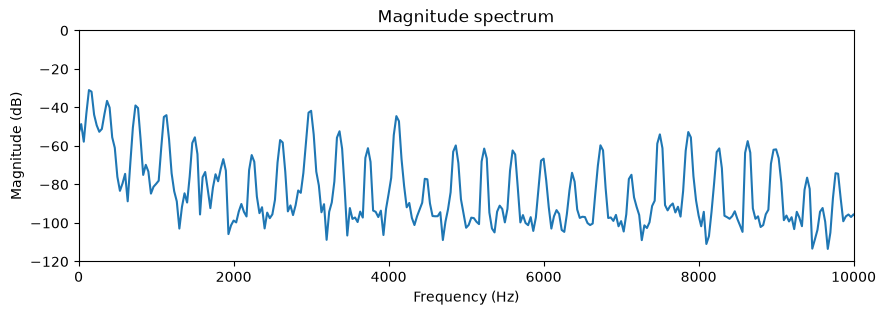

In [13]:
start = int(0.25 * fs)
end = int(0.28 * fs)
fragment = reference_audio[start:end]

ax = plot_spectrum(fragment, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 10000])

plt.show()

#### 1.2 Questions

1. What are the strongest peaks in the magnitude spectrum? To what harmonics do they correspond?
   - The strongest peak occurs at the fundamental frequency near 102 Hz (k = 1) at -31 dB. The next peaks appear near 370 Hz (-36 dB), 750 Hz (-39 dB), and 1130 Hz (-44 dB), which are the other higher pitches that make up the sound. 

2. Do you see a fundamental frequency and its harmonics? How did you identify them?
   - Yes, the fundamental frequency is identified by the first peak, around 102 Hz. The harmonics are identified by observing distinct peaks spaced out at integer multiples across higher frequencies.  

3. How would the spectrum change if the fragment were taken from a different part of the signal?
   - Taking a fragment from a different part would produce either a broader noise floor with higher energy or a reduced overall magnitude with higher harmonic peaks fading away much faster than the fundamental frequency.

#### 1.3 Spectrogram of the whole sound

The FFT of one fragment gives a local snapshot, but a sound changes over time. A spectrogram shows how the frequency content evolves across the whole signal.

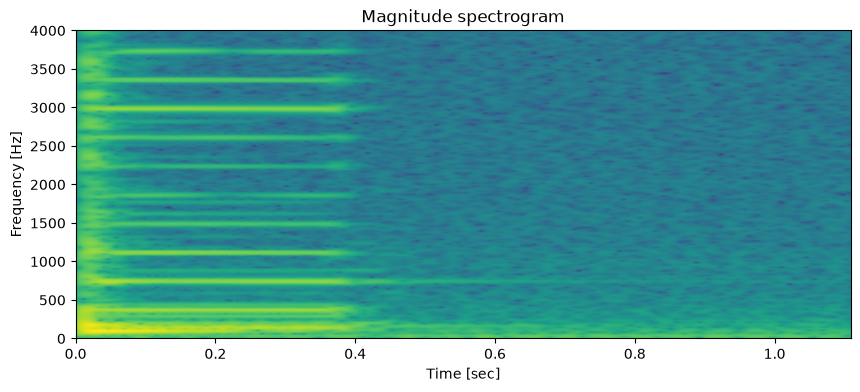

In [14]:
n_fft = 2048
hop_length = 256

ax = plot_spectrogram(reference_audio, sr=fs, N=n_fft, H=hop_length)
ax.set_ylim([0, 4000])
plt.show()

#### 1.4 Questions

1. Which frequencies are present for most of the sound? What does it mean from a perceptual point of view?
   - The lowest frequency bands below 500 Hz remain visible and bright for the longest duration, continuing past 0.4 seconds. Perceptually, this means that even as the higher overtones disappear quickly, our ears continue to hear the steady fundamental musical pitch of the note throughout the sustain phase.

2. Do the bright bands stay fixed or do they change over time? What does it mean?
   - The bright horizontal bands stay fixed at specific, parallel frequency lines, but their intensity dims and cuts off over time. The fixed horizontal position indicates that the fundamental pitch remains stable, while the fading brightness represents the decay in sound volume/energy over time.

3. How does the spectrogram help explain why the sound changes over time? Describe the sound evolution.
   - The spectrogram shows an initial vertical splash of bright energy across all frequencies at t = 0s (representing the pluck strike noise). Between 0s and 0.4s, a dense grid of parallel harmonic bands (extending up to 3700 Hz) sustains brightly. At around 0.4s, all high-frequency harmonics abruptly drop off, leaving only the lowest fundamental frequency components below 500 Hz to fade into the background noise floor. 

#### 1.4 Fragment comparison

Repeat the spectral analysis for a different fragment of the signal and compare the magnitude spectra. Explain the difference.

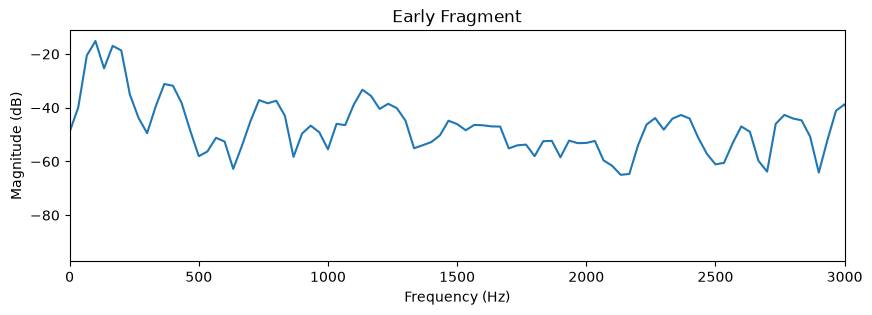

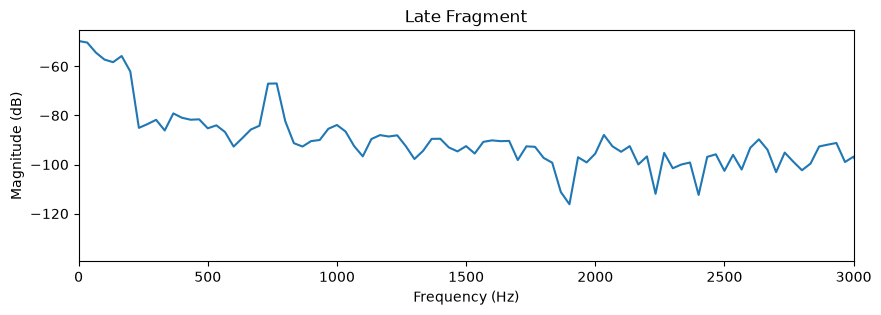

In [18]:
frag1 = reference_audio[int(0.01*fs):int(0.04*fs)]
ax1 = plot_spectrum(frag1, sr=fs)
ax1.set_xlim([0, 3000])
ax1.set_title("Early Fragment")

frag2 = reference_audio[int(0.5*fs):int(0.53*fs)]
ax2 = plot_spectrum(frag2, sr=fs)
ax2.set_xlim([0, 3000])
ax2.set_title("Late Fragment")

plt.show()

First spectrum: it displays maximum energy and a set of high-frequency harmonics spanning all the way due to the initial mechanical impact of the pluck.   

Second spectrum: the overall magnitude drops significantly across the entire spectrum. High-frequency overtones decay much faster than lower frequencies due to string damping, leaving only weak low-frequency components above the noise floor. 

Choose a time where several harmonics are visible in the spectrogram and plot the spectrum at that time. Can you explain the result?

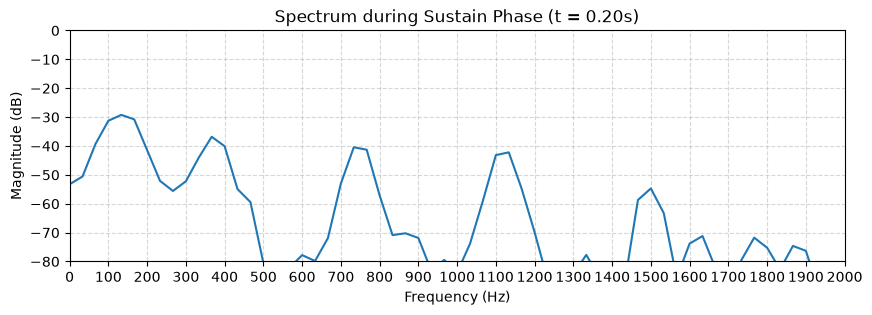

In [16]:
# Select fragment during sustain (0.20s to 0.23s) where harmonics are strong
start_sustain = int(0.20 * fs)
end_sustain = int(0.23 * fs)
frag_sustain = reference_audio[start_sustain:end_sustain]

# Plot magnitude spectrum zoom-in on lower frequencies (0 - 2000 Hz)
ax = plot_spectrum(frag_sustain, sr=fs)
ax.set_xlim([0, 2000])
ax.set_ylim([-80, 0])
ax.set_xticks(np.arange(0, 2001, 100))
ax.grid(True, linestyle='--', alpha=0.5)

plt.title("Spectrum during Sustain Phase (t = 0.20s)")
plt.show()

The highest peak occurs at the fundamental frequency (102-130 Hz) at -29 dB. As said before, subsequent major peaks appear near integer multiples of the fundamental (around 370 Hz, 740 Hz, 1130 Hz and 1500 Hz).

Use the plots to estimate the weights of the fundamental frequency and a few harmonics. Store them in a list for later use. Be careful because the amplitude of the plot are in dB and you will need them in a linear scale, from 0 to 1, where 1 should be the maximum value of the spectrum. So you need to perform the conversion from dB to linear.

In [17]:
weights = []  

# Peak dB measurements taken directly from the sustain spectrum plot
peaks_dB = np.array([-29.0, -37.0, -40.0, -42.0, -54.0])

# Convert dB to linear magnitude using 10^(dB / 20)
weights_linear = 10**(peaks_dB / 20.0)

# Normalize so the maximum value (fundamental) equals 1.0
weights = list(weights_linear / np.max(weights_linear))

print("Measured harmonic weights (linear 0 to 1):")
for i, w in enumerate(weights, start=1):
    print(f"Weight {i}: {w:.4f}")

Measured harmonic weights (linear 0 to 1):
Weight 1: 1.0000
Weight 2: 0.3981
Weight 3: 0.2818
Weight 4: 0.2239
Weight 5: 0.0562


### 2. Synthesis

Now we will use the harmonic synthesis idea from previous labs to build a signal from the estimated spectral weights.

In [19]:
def synthesize(f0, phi, Ak, t):
    y = np.zeros_like(t, dtype=float)
    for k in range(1, len(Ak) + 1):
        y += Ak[k - 1] * np.cos(2 * np.pi * k * f0 * t + k * phi - (k - 1) * np.pi / 2)
    return y

#### 2.1 Write the code

Use the `synthesize` function to generate a signal with the weights from part 1.3 and the fundamental frequency and phase from earlier labs. Plot the synthesized signal together with the reference so you can compare them directly.

In [20]:
# Setup parameters from earlier labs
f0 = 102.0          # Fundamental frequency (Hz)
phi = -0.5          # Initial phase from previous lab
duration = len(reference_audio) / fs
t = np.arange(0, duration, 1.0 / fs)

# Synthesize the audio signal using the weights from Part 1.4
syn_audio = synthesize(f0, phi, weights, t)

# Scale/Normalize peak amplitude to match the reference signal (~0.6 peak)
syn_audio = 0.6 * (syn_audio / np.max(np.abs(syn_audio)))

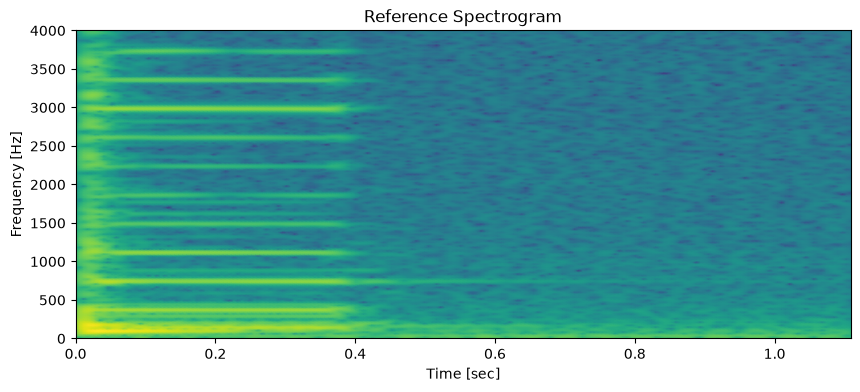

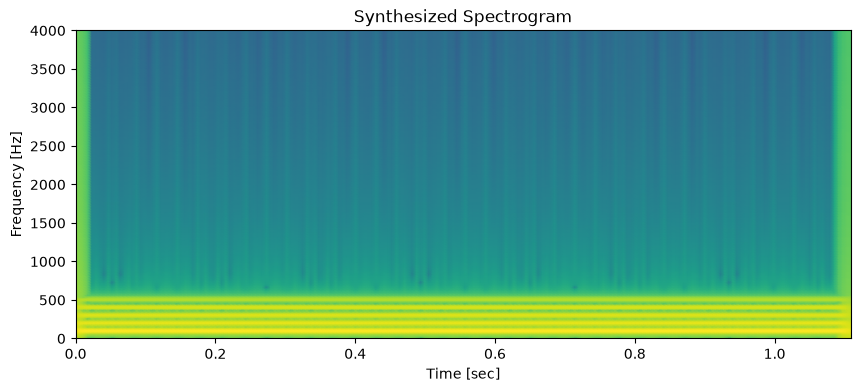

In [21]:
import matplotlib.pyplot as plt

# Time-Domain Comparison (6 periods) 
T = 1.0 / f0
t_start = 0.03
t_end = t_start + 6 * T

plot_signals([reference_audio, syn_audio], fs, t_start=t_start, t_end=t_end, name=['Reference', 'Synthesized'])

# Spectrogram Comparison 
n_fft = 2048
hop_length = 256

# Reference Spectrogram
ax1 = plot_spectrogram(reference_audio, sr=fs, N=n_fft, H=hop_length)
ax1.set_ylim([0, 4000])
plt.title("Reference Spectrogram")
plt.show()

# Synthesized Spectrogram
ax2 = plot_spectrogram(syn_audio, sr=fs, N=n_fft, H=hop_length)
ax2.set_ylim([0, 4000])
plt.title("Synthesized Spectrogram")
plt.show()

#### 2.2 Questions

1. What do you notice when you compare the synthesized spectrogram with the reference spectrogram?
   - The reference spectrogram shows dynamic horizontal bands that fade out over time around t = 0.4 s, along with high-frequency noise from the pluck attack.   
   - The synthesized spectrogram displays static horizontal bands with completely constant intensity from 0 to 1.1 s, without any time-varying decay.   

2. Which parts of the sound are reproduced well, and which parts are still missing or different?
   - Reproduced well: The fundamental pitch and the core periodic waveform shape match the reference signal well during the sustain phase, as seen in the overlapping time-domain plot.   
   - Missing or Different:
      - Exponential decay: The synthesized signal lacks an amplitude envelope, so it stays at full volume instead of fading away.   
      - Attack transient: The initial pluck strike noise is missing entirely.   
      - Phase alignment: The slight offset in the time-domain overlay shows that the phase spectrum of the reference signal is not perfectly matched by a fixed phase angle.  